在一次会话开始后的前 5 次行为结束时，预测该会话后续是否会发生购买。

label = 1：第 5 次行为之后，该会话发生购买
label = 0：第 5 次行为之后，该会话没有购买

用户刚开始访问
→ 观察前几次行为
→ 预测是否可能购买
→ 决定是否触达优惠或推荐

In [1]:
import sys
import duckdb
import pandas as pd
import sklearn
import lightgbm

print("Python 路径：", sys.executable)
print("scikit-learn 版本：", sklearn.__version__)
print("LightGBM 版本：", lightgbm.__version__)

Python 路径： C:\Users\29443\Documents\实习\ecommerce-conversion\.venv\Scripts\python.exe
scikit-learn 版本： 1.9.0
LightGBM 版本： 4.7.0


In [2]:
import sys
from pathlib import Path

import duckdb
import pandas as pd

print("Python 路径：", sys.executable)
print("DuckDB 版本：", duckdb.__version__)

Python 路径： C:\Users\29443\Documents\实习\ecommerce-conversion\.venv\Scripts\python.exe
DuckDB 版本： 1.5.5


# 会话购买意向预测

## 1. 预测任务定义

本项目以 `user_session` 为样本单位，在会话前 5 次行为结束时，预测该会话后续是否发生购买。

- 样本单位：一个 `user_session`；
- 观察窗口：会话开始后的前 5 条行为；
- 标签为 1：第 5 条行为之后，该会话发生过购买；
- 标签为 0：第 5 条行为之后，该会话没有发生购买。

所有特征只能使用第 5 条行为及之前的信息，避免使用未来行为造成数据泄漏。

In [3]:
from pathlib import Path

clean_path = Path(
    "../data/processed/events_2019_10_clean.parquet"
).resolve()

clean_sql_path = clean_path.as_posix()

print("数据文件：", clean_path)
print("文件存在：", clean_path.exists())

数据文件： C:\Users\29443\Documents\实习\ecommerce-conversion\data\processed\events_2019_10_clean.parquet
文件存在： True


## 2. 会话长度检查

模型需要读取每个会话的前 5 次行为，因此先检查会话中至少有 5 条事件的比例。

少于 5 条行为的会话无法构造完整的观察窗口，本次基础模型暂时排除这些会话。

In [4]:
session_length_summary = duckdb.sql(f"""
    WITH session_counts AS (
        SELECT
            user_session,
            COUNT(*) AS event_count
        FROM read_parquet('{clean_sql_path}')
        GROUP BY user_session
    )

    SELECT
        COUNT(*) AS total_sessions,

        COUNT(*) FILTER (
            WHERE event_count >= 5
        ) AS sessions_with_at_least_5_events,

        COUNT(*) FILTER (
            WHERE event_count < 5
        ) AS sessions_with_less_than_5_events,

        ROUND(
            COUNT(*) FILTER (
                WHERE event_count >= 5
            ) * 100.0 / COUNT(*),
            2
        ) AS usable_session_pct,

        ROUND(MEDIAN(event_count), 2)
            AS median_event_count,

        ROUND(AVG(event_count), 2)
            AS avg_event_count,

        MAX(event_count)
            AS max_event_count

    FROM session_counts
""").df()

session_length_summary.T

,0
total_sessions,9244421.00
sessions_with_at_least_5_events,2678416.00
sessions_with_less_than_5_events,6566005.00
usable_session_pct,28.97
median_event_count,2.00
avg_event_count,4.59
max_event_count,1159.00


### 会话长度检查结论

清洗后共有 9,244,421 个会话，其中 2,678,416 个会话至少包含 5 条行为，占 28.97%。会话行为数量分布具有明显长尾特征：中位数为 2，平均值为 4.59，最长会话包含 1,159 条行为。

本项目只保留至少包含 5 条行为的会话，不对短会话进行人为补齐。进一步地，如果会话在前 5 条行为中已经发生购买，则该会话在预测时点已经完成目标，不纳入“后续购买预测”样本。

In [5]:
#时只构造样本数量和标签，不训练模型
session_label_summary = duckdb.sql(f"""
    WITH ranked_events AS (
        SELECT
            user_session,
            event_time,
            event_type,
            ROW_NUMBER() OVER (
                PARTITION BY user_session
                ORDER BY
                    event_time,
                    event_type,
                    product_id,
                    category_id,
                    price,
                    user_id
            ) AS event_number
        FROM read_parquet('{clean_sql_path}')
    ),

    session_cutoff AS (
        SELECT
            user_session,
            MAX(event_time) FILTER (
                WHERE event_number = 5
            ) AS cutoff_time,

            MAX(event_type = 'purchase') FILTER (
                WHERE event_number <= 5
            ) AS purchased_in_first_5,

            MAX(event_number) AS total_event_count
        FROM ranked_events
        GROUP BY user_session
        HAVING MAX(event_number) >= 5
    ),

    eligible_sessions AS (
        SELECT *
        FROM session_cutoff
        WHERE purchased_in_first_5 = FALSE
    ),

    labeled_sessions AS (
        SELECT
            e.user_session,

            CASE
                WHEN MAX(
                    e.event_type = 'purchase'
                    AND e.event_number > 5
                )
                THEN 1
                ELSE 0
            END AS label

        FROM ranked_events AS e
        INNER JOIN eligible_sessions AS s
            ON e.user_session = s.user_session
        GROUP BY e.user_session
    )

    SELECT
        COUNT(*) AS eligible_session_count,

        SUM(label) AS positive_sessions,

        COUNT(*) - SUM(label) AS negative_sessions,

        ROUND(
            SUM(label) * 100.0 / COUNT(*),
            2
        ) AS positive_rate_pct

    FROM labeled_sessions
""").df()

session_label_summary.T

,0
eligible_session_count,2508382.00
positive_sessions,178621.00
negative_sessions,2329761.00
positive_rate_pct,7.12


### 建模样本和标签结论

满足至少 5 条行为且前 5 条行为中尚未购买的会话共有 2,508,382 个。

其中：

- `label = 1` 的会话有 178,621 个，占 7.12%，表示第 5 条行为之后发生购买；
- `label = 0` 的会话有 2,329,761 个，占 92.88%，表示第 5 条行为之后没有购买。

当前任务属于类别不平衡分类问题，因此不能只使用准确率评价模型，后续将重点关注 PR-AUC、Recall@Top 10% 和 Lift 等指标。

## 3. 构造会话前 5 次行为特征

所有特征均只使用会话前 5 条行为，标签只使用第 5 条行为之后是否发生购买。

因此，模型在预测时点不会看到未来行为，避免数据泄漏。

In [6]:
feature_path = Path(
    "../data/processed/session_purchase_features.parquet"
).resolve()

feature_sql_path = feature_path.as_posix()

if feature_path.exists():
    print("特征文件已经存在，跳过生成。")
else:
    con = duckdb.connect()

    con.execute(f"""
        COPY (
            WITH ranked_events AS (
                SELECT
                    user_session,
                    event_time,
                    event_type,
                    product_id,
                    category_id,
                    brand,
                    price,

                    ROW_NUMBER() OVER (
                        PARTITION BY user_session
                        ORDER BY
                            event_time,
                            event_type,
                            product_id,
                            category_id,
                            price,
                            user_id
                    ) AS event_number
                FROM read_parquet('{clean_sql_path}')
            ),

            eligible_sessions AS (
                SELECT
                    user_session
                FROM ranked_events
                GROUP BY user_session
                HAVING COUNT(*) >= 5
                   AND SUM(
                       CASE
                           WHEN event_number <= 5
                            AND event_type = 'purchase'
                           THEN 1
                           ELSE 0
                       END
                   ) = 0
            ),

            session_features AS (
                SELECT
                    e.user_session,

                    EXTRACT(
                        HOUR FROM MIN(e.event_time)
                    ) AS session_start_hour,

                    EXTRACT(
                        DOW FROM MIN(e.event_time)
                    ) AS session_start_dow,

                    SUM(
                        CASE WHEN e.event_type = 'view'
                             THEN 1 ELSE 0 END
                    ) AS view_count_first_5,

                    SUM(
                        CASE WHEN e.event_type = 'cart'
                             THEN 1 ELSE 0 END
                    ) AS cart_count_first_5,

                    COUNT(DISTINCT e.product_id)
                        AS distinct_product_count_first_5,

                    COUNT(DISTINCT e.category_id)
                        AS distinct_category_count_first_5,

                    COUNT(DISTINCT e.brand)
                        FILTER (WHERE e.brand <> 'unknown')
                        AS distinct_brand_count_first_5,

                    AVG(e.price)
                        AS avg_price_first_5,

                    MAX(e.price)
                        AS max_price_first_5,

                    MIN(e.price)
                        AS min_price_first_5,

                    SUM(
                        CASE WHEN e.price = 0
                             THEN 1 ELSE 0 END
                    ) AS zero_price_count_first_5,

                    EPOCH(
                        MAX(e.event_time)
                        - MIN(e.event_time)
                    ) AS first_5_duration_seconds

                FROM ranked_events AS e
                INNER JOIN eligible_sessions AS s
                    ON e.user_session = s.user_session
                WHERE e.event_number <= 5
                GROUP BY e.user_session
            ),

            session_labels AS (
                SELECT
                    e.user_session,

                    MAX(
                        CASE
                            WHEN e.event_number > 5
                             AND e.event_type = 'purchase'
                            THEN 1
                            ELSE 0
                        END
                    ) AS label

                FROM ranked_events AS e
                INNER JOIN eligible_sessions AS s
                    ON e.user_session = s.user_session
                GROUP BY e.user_session
            )

            SELECT
                f.*,
                l.label
            FROM session_features AS f
            INNER JOIN session_labels AS l
                ON f.user_session = l.user_session
        )
        TO '{feature_sql_path}'
        (
            FORMAT PARQUET,
            COMPRESSION ZSTD
        )
    """)

    con.close()
    print("特征文件生成完成。")

print("特征文件存在：", feature_path.exists())
print(
    "特征文件大小：",
    round(feature_path.stat().st_size / 1024**3, 2),
    "GB"
)

特征文件已经存在，跳过生成。
特征文件存在： True
特征文件大小： 0.08 GB


In [7]:
#检查特征表
feature_schema = duckdb.sql(f"""
    DESCRIBE SELECT *
    FROM read_parquet('{feature_sql_path}')
""").df()

feature_schema

,column_name,column_type,null,key,default,extra
0,user_session,VARCHAR,YES,None,None,None
1,session_start_hour,BIGINT,YES,None,None,None
2,session_start_dow,BIGINT,YES,None,None,None
3,view_count_first_5,DOUBLE,YES,None,None,None
4,cart_count_first_5,DOUBLE,YES,None,None,None
5,distinct_product_count_first_5,BIGINT,YES,None,None,None
6,distinct_category_count_first_5,BIGINT,YES,None,None,None
7,distinct_brand_count_first_5,BIGINT,YES,None,None,None
8,avg_price_first_5,DOUBLE,YES,None,None,None
9,max_price_first_5,DOUBLE,YES,None,None,None


In [8]:
#检查样本预览
feature_preview = duckdb.sql(f"""
    SELECT *
    FROM read_parquet('{feature_sql_path}')
    LIMIT 5
""").df()

feature_preview

,user_session,session_start_hour,session_start_dow,view_count_first_5,cart_count_first_5,distinct_product_count_first_5,distinct_category_count_first_5,distinct_brand_count_first_5,avg_price_first_5,max_price_first_5,min_price_first_5,zero_price_count_first_5,first_5_duration_seconds,label
0,31a52d66-e56b-4f2c-8149-484ccaf3c247,13,3,5.0,0.0,4,1,1,348.376,411.83,257.87,0.0,195.0,0
1,31a86052-0b1c-4044-91f4-0a7b99c79ac6,10,0,5.0,0.0,2,1,1,230.750,230.79,230.74,0.0,354.0,1
2,31ad6541-82f9-4b61-9594-b6c9166eb29d,7,2,5.0,0.0,2,1,1,254.322,283.77,246.96,0.0,977.0,0
3,31afc8ac-48f1-41c7-bc63-22051e3ac2fe,13,5,5.0,0.0,4,2,2,286.008,411.59,167.03,0.0,148.0,0
4,31b24a05-2bf4-47c7-ab2e-319ed85e83e2,17,6,5.0,0.0,5,1,2,89.834,106.05,79.02,0.0,281.0,0


In [9]:
#检查缺失值
feature_missing = duckdb.sql(f"""
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE session_start_hour IS NULL
        ) AS session_start_hour_missing,

        COUNT(*) FILTER (
            WHERE session_start_dow IS NULL
        ) AS session_start_dow_missing,

        COUNT(*) FILTER (
            WHERE avg_price_first_5 IS NULL
        ) AS avg_price_missing,

        COUNT(*) FILTER (
            WHERE first_5_duration_seconds IS NULL
        ) AS duration_missing,

        COUNT(*) FILTER (
            WHERE label IS NULL
        ) AS label_missing

    FROM read_parquet('{feature_sql_path}')
""").df()

feature_missing.T

,0
total_rows,2508382
session_start_hour_missing,0
session_start_dow_missing,0
avg_price_missing,0
duration_missing,0
label_missing,0


In [10]:
#检查数值特征范围
feature_stats = duckdb.sql(f"""
    SELECT
        MIN(session_start_hour) AS min_start_hour,
        MAX(session_start_hour) AS max_start_hour,

        MIN(session_start_dow) AS min_start_dow,
        MAX(session_start_dow) AS max_start_dow,

        MIN(view_count_first_5) AS min_view_count,
        MAX(view_count_first_5) AS max_view_count,

        MIN(cart_count_first_5) AS min_cart_count,
        MAX(cart_count_first_5) AS max_cart_count,

        MIN(distinct_product_count_first_5)
            AS min_product_count,
        MAX(distinct_product_count_first_5)
            AS max_product_count,

        MIN(avg_price_first_5) AS min_avg_price,
        MAX(avg_price_first_5) AS max_avg_price,

        MIN(first_5_duration_seconds)
            AS min_duration_seconds,
        MAX(first_5_duration_seconds)
            AS max_duration_seconds

    FROM read_parquet('{feature_sql_path}')
""").df()

feature_stats.T

,0
min_start_hour,0.00
max_start_hour,23.00
min_start_dow,0.00
max_start_dow,6.00
min_view_count,0.00
max_view_count,5.00
min_cart_count,0.00
max_cart_count,5.00
min_product_count,1.00
max_product_count,5.00


### 特征质量检查结论

特征表共有 2,508,382 条会话样本，关键特征和标签均无实际缺失。小时、星期、前 5 次行为数量和价格范围符合预期。

`DESCRIBE` 中的 `null = YES` 仅表示字段类型允许存储空值，不代表数据中实际存在缺失值。

部分会话前 5 次行为的持续时间较长，最大达到 2,565,947 秒，约 29.70 天。这说明原始 `user_session` 可能并不总是代表一次短时间连续访问，需要进一步检查持续时间分布。

In [11]:
#检查持续时间分布
duration_summary = duckdb.sql(f"""
    SELECT
        ROUND(
            QUANTILE_CONT(first_5_duration_seconds, 0.50),
            2
        ) AS duration_p50,

        ROUND(
            QUANTILE_CONT(first_5_duration_seconds, 0.75),
            2
        ) AS duration_p75,

        ROUND(
            QUANTILE_CONT(first_5_duration_seconds, 0.90),
            2
        ) AS duration_p90,

        ROUND(
            QUANTILE_CONT(first_5_duration_seconds, 0.95),
            2
        ) AS duration_p95,

        ROUND(
            QUANTILE_CONT(first_5_duration_seconds, 0.99),
            2
        ) AS duration_p99,

        MAX(first_5_duration_seconds)
            AS max_duration,

        COUNT(*) FILTER (
            WHERE first_5_duration_seconds > 1800
        ) AS over_30_minute_count,

        COUNT(*) FILTER (
            WHERE first_5_duration_seconds > 86400
        ) AS over_1_day_count

    FROM read_parquet('{feature_sql_path}')
""").df()

duration_summary.T

,0
duration_p50,195.0
duration_p75,325.0
duration_p90,565.0
duration_p95,873.0
duration_p99,3457.0
max_duration,2565947.0
over_30_minute_count,51626.0
over_1_day_count,3821.0


### 会话持续时间处理

前 5 次行为持续时间的中位数为 195 秒，99 分位数为 3,457 秒。共有 51,626 个样本超过 30 分钟，3,821 个样本超过 1 天，最长达到约 29.7 天。

本项目不直接删除长会话，因为无法判断它们是用户真实长时间访问，还是原始数据中的会话 ID 长时间未更新。后续保留原始持续时间，同时增加按 P99 截断的持续时间和 `log1p` 变换后的持续时间，分别用于模型解释和降低极端值影响。

此外，为实现时间外验证，特征表将补充会话首次行为时间 `session_start_time` 及其日期 `session_start_date`。

In [12]:
#补充时间字段和处理后的持续时间
feature_v2_path = Path(
    "../data/processed/session_purchase_features_v2.parquet"
).resolve()

feature_v2_sql_path = feature_v2_path.as_posix()

if feature_v2_path.exists():
    print("增强特征文件已经存在，跳过生成。")
else:
    con = duckdb.connect()

    con.execute(f"""
        COPY (
            WITH session_starts AS (
                SELECT
                    user_session,
                    MIN(event_time) AS session_start_time
                FROM read_parquet('{clean_sql_path}')
                GROUP BY user_session
            ),

            p99_value AS (
                SELECT
                    QUANTILE_CONT(
                        first_5_duration_seconds,
                        0.99
                    ) AS duration_p99
                FROM read_parquet('{feature_sql_path}')
            )

            SELECT
                f.*,
                s.session_start_time,
                CAST(s.session_start_time AS DATE)
                    AS session_start_date,

                LEAST(
                    f.first_5_duration_seconds,
                    p.duration_p99
                ) AS duration_capped_seconds,

                LN(
                    1 + f.first_5_duration_seconds
                ) AS log_duration_seconds

            FROM read_parquet('{feature_sql_path}') AS f
            INNER JOIN session_starts AS s
                ON f.user_session = s.user_session
            CROSS JOIN p99_value AS p
        )
        TO '{feature_v2_sql_path}'
        (
            FORMAT PARQUET,
            COMPRESSION ZSTD
        )
    """)

    con.close()
    print("增强特征文件生成完成。")

print("文件存在：", feature_v2_path.exists())

if feature_v2_path.exists():
    print(
        "文件大小：",
        round(feature_v2_path.stat().st_size / 1024**3, 2),
        "GB"
    )

增强特征文件已经存在，跳过生成。
文件存在： True
文件大小： 0.09 GB


In [13]:
#检验
feature_v2_check = duckdb.sql(f"""
    SELECT
        COUNT(*) AS sample_count,
        COUNT(DISTINCT user_session) AS distinct_session_count,
        MIN(session_start_time) AS min_session_start,
        MAX(session_start_time) AS max_session_start,
        MIN(duration_capped_seconds)
            AS min_capped_duration,
        MAX(duration_capped_seconds)
            AS max_capped_duration,
        MIN(log_duration_seconds)
            AS min_log_duration,
        MAX(log_duration_seconds)
            AS max_log_duration,
        SUM(label) AS positive_count
    FROM read_parquet('{feature_v2_sql_path}')
""").df()

feature_v2_check.T

,0
sample_count,2508382
distinct_session_count,2508382
min_session_start,2019-10-01 00:00:01
max_session_start,2019-10-31 23:58:53
min_capped_duration,0.0
max_capped_duration,3457.0
min_log_duration,0.0
max_log_duration,14.757839
positive_count,178621.0


## 4. 按时间切分训练集、验证集和测试集

本项目按照会话首次行为日期切分数据：

- 训练集：2019-10-01 至 2019-10-21；
- 验证集：2019-10-22 至 2019-10-26；
- 测试集：2019-10-27 至 2019-10-31。

训练集用于学习模型参数，验证集用于选择模型和阈值，测试集只用于最后一次评价。

In [14]:
#确认每天都有足够样本，并观察不同日期的购买比例是否差异很大。
date_distribution = duckdb.sql(f"""
    SELECT
        session_start_date,
        COUNT(*) AS sample_count,
        SUM(label) AS positive_count,
        ROUND(
            AVG(label) * 100,
            2
        ) AS positive_rate_pct
    FROM read_parquet('{feature_v2_sql_path}')
    GROUP BY session_start_date
    ORDER BY session_start_date
""").df()

date_distribution

,session_start_date,sample_count,positive_count,positive_rate_pct
0,2019-10-01,74484,4254.0,5.71
1,2019-10-02,70656,4357.0,6.17
2,2019-10-03,66610,4239.0,6.36
3,2019-10-04,85285,6962.0,8.16
4,2019-10-05,79458,6081.0,7.65
5,2019-10-06,78332,6031.0,7.70
6,2019-10-07,70722,4773.0,6.75
7,2019-10-08,81653,5123.0,6.27
8,2019-10-09,79966,5117.0,6.40
9,2019-10-10,74950,4899.0,6.54


In [15]:
#统计三个数据集的规模
split_summary = duckdb.sql(f"""
    SELECT
        CASE
            WHEN session_start_date <= DATE '2019-10-21'
                THEN 'train'
            WHEN session_start_date <= DATE '2019-10-26'
                THEN 'validation'
            ELSE 'test'
        END AS dataset,

        COUNT(*) AS sample_count,
        SUM(label) AS positive_count,
        COUNT(*) - SUM(label) AS negative_count,

        ROUND(
            AVG(label) * 100,
            2
        ) AS positive_rate_pct,

        MIN(session_start_date) AS start_date,
        MAX(session_start_date) AS end_date

    FROM read_parquet('{feature_v2_sql_path}')
    GROUP BY dataset
    ORDER BY
        CASE dataset
            WHEN 'train' THEN 1
            WHEN 'validation' THEN 2
            WHEN 'test' THEN 3
        END
""").df()

split_summary

,dataset,sample_count,positive_count,negative_count,positive_rate_pct,start_date,end_date
0,train,1729816,124296.0,1605520.0,7.19,2019-10-01,2019-10-21
1,validation,405672,29949.0,375723.0,7.38,2019-10-22,2019-10-26
2,test,372894,24376.0,348518.0,6.54,2019-10-27,2019-10-31


In [16]:
#准备模型数据
model_data = duckdb.sql(f"""
    SELECT
        session_start_date,
        session_start_hour,
        session_start_dow,
        view_count_first_5,
        cart_count_first_5,
        distinct_product_count_first_5,
        distinct_category_count_first_5,
        distinct_brand_count_first_5,
        avg_price_first_5,
        max_price_first_5,
        min_price_first_5,
        zero_price_count_first_5,
        duration_capped_seconds,
        log_duration_seconds,
        label
    FROM read_parquet('{feature_v2_sql_path}')
""").df()

print("模型数据行数：", len(model_data))
print("模型数据列数：", model_data.shape[1])
model_data.head()

模型数据行数： 2508382
模型数据列数： 15


,session_start_date,session_start_hour,session_start_dow,view_count_first_5,cart_count_first_5,distinct_product_count_first_5,distinct_category_count_first_5,distinct_brand_count_first_5,avg_price_first_5,max_price_first_5,min_price_first_5,zero_price_count_first_5,duration_capped_seconds,log_duration_seconds,label
0,2019-10-01,10,2,5.0,0.0,4,1,1,185.026,215.71,123.30,0.0,333.0,5.811141,0
1,2019-10-01,10,2,5.0,0.0,3,2,2,118.464,179.35,51.46,0.0,475.0,6.165418,0
2,2019-10-01,9,2,5.0,0.0,5,2,2,79.406,155.22,37.32,0.0,361.0,5.891644,0
3,2019-10-01,10,2,5.0,0.0,5,4,3,115.620,218.74,17.54,0.0,642.0,6.466145,0
4,2019-10-01,9,2,5.0,0.0,2,1,2,205.054,205.48,203.35,0.0,701.0,6.553933,1


In [17]:
#执行时间切分
model_data["session_start_date"] = pd.to_datetime(
    model_data["session_start_date"]
)

train_data = model_data[
    model_data["session_start_date"]
    <= pd.Timestamp("2019-10-21")
].copy()

validation_data = model_data[
    (
        model_data["session_start_date"]
        >= pd.Timestamp("2019-10-22")
    )
    & (
        model_data["session_start_date"]
        <= pd.Timestamp("2019-10-26")
    )
].copy()

test_data = model_data[
    model_data["session_start_date"]
    >= pd.Timestamp("2019-10-27")
].copy()

print("训练集：", train_data.shape)
print("验证集：", validation_data.shape)
print("测试集：", test_data.shape)

训练集： (1729816, 15)
验证集： (405672, 15)
测试集： (372894, 15)


## 5. 逻辑回归基线模型

逻辑回归用于预测会话在前 5 次行为后是否继续购买。

模型不使用：

- `user_session`：随机字符串，没有预测意义；
- `session_start_date`：只用于时间切分，不作为模型特征；
- `label`：预测目标，不能作为输入特征。

由于正样本比例约为 7.12%，训练时使用 `class_weight="balanced"`。

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

feature_columns = [
    "session_start_hour",
    "session_start_dow",
    "view_count_first_5",
    "cart_count_first_5",
    "distinct_product_count_first_5",
    "distinct_category_count_first_5",
    "distinct_brand_count_first_5",
    "avg_price_first_5",
    "max_price_first_5",
    "min_price_first_5",
    "zero_price_count_first_5",
    "duration_capped_seconds",
    "log_duration_seconds",
]

X_train = train_data[feature_columns]
y_train = train_data["label"]

X_validation = validation_data[feature_columns]
y_validation = validation_data["label"]

X_test = test_data[feature_columns]
y_test = test_data["label"]

print("训练特征形状：", X_train.shape)
print("验证特征形状：", X_validation.shape)
print("测试特征形状：", X_test.shape)
print("训练集正样本比例：", round(y_train.mean() * 100, 2), "%")

训练特征形状： (1729816, 13)
验证特征形状： (405672, 13)
测试特征形状： (372894, 13)
训练集正样本比例： 7.19 %


In [19]:
#建立逻辑回归流程
logistic_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

logistic_model.fit(X_train, y_train)

print("逻辑回归训练完成")
'''
SimpleImputer：如果以后出现缺失值，用中位数填充；
StandardScaler：将不同量纲的特征标准化；
LogisticRegression：训练分类模型。
'''

逻辑回归训练完成


'\nSimpleImputer：如果以后出现缺失值，用中位数填充；\nStandardScaler：将不同量纲的特征标准化；\nLogisticRegression：训练分类模型。\n'

In [20]:
#计算预测概率
validation_proba = logistic_model.predict_proba(
    X_validation
)[:, 1]

test_proba = logistic_model.predict_proba(
    X_test
)[:, 1]

print("验证集预测概率示例：")
print(validation_proba[:10])

验证集预测概率示例：
[0.37777172 0.38953271 0.48658498 0.72837388 0.91300786 0.36708566
 0.31052102 0.41583961 0.30431859 0.20576522]


In [21]:
#计算基础评价指标
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

validation_roc_auc = roc_auc_score(
    y_validation,
    validation_proba
)

validation_pr_auc = average_precision_score(
    y_validation,
    validation_proba
)

test_roc_auc = roc_auc_score(
    y_test,
    test_proba
)

test_pr_auc = average_precision_score(
    y_test,
    test_proba
)

print(
    "验证集 ROC-AUC：",
    round(validation_roc_auc, 4)
)

print(
    "验证集 PR-AUC：",
    round(validation_pr_auc, 4)
)

print(
    "测试集 ROC-AUC：",
    round(test_roc_auc, 4)
)

print(
    "测试集 PR-AUC：",
    round(test_pr_auc, 4)
)

验证集 ROC-AUC： 0.7136
验证集 PR-AUC： 0.2262
测试集 ROC-AUC： 0.6935
测试集 PR-AUC： 0.2016


In [22]:
#计算TOP10%Lift
def top_k_metrics(y_true, probabilities, top_fraction=0.10):
    result = pd.DataFrame({
        "label": pd.Series(y_true).reset_index(drop=True),
        "probability": pd.Series(probabilities).reset_index(drop=True),
    })

    result = result.sort_values(
        "probability",
        ascending=False
    ).reset_index(drop=True)

    top_count = max(
        1,
        int(len(result) * top_fraction)
    )

    top_result = result.iloc[:top_count]

    overall_rate = result["label"].mean()
    top_rate = top_result["label"].mean()
    captured_positive_rate = (
        top_result["label"].sum()
        / result["label"].sum()
    )

    return {
        "top_fraction_pct": top_fraction * 100,
        "top_sample_count": top_count,
        "top_positive_rate_pct": round(top_rate * 100, 2),
        "overall_positive_rate_pct": round(
            overall_rate * 100,
            2
        ),
        "recall_at_top_pct": round(
            captured_positive_rate * 100,
            2
        ),
        "lift_at_top": round(
            top_rate / overall_rate,
            2
        ),
    }


validation_top10 = top_k_metrics(
    y_validation,
    validation_proba
)

test_top10 = top_k_metrics(
    y_test,
    test_proba
)

print("验证集 Top 10%：")
print(validation_top10)

print("\n测试集 Top 10%：")
print(test_top10)

验证集 Top 10%：
{'top_fraction_pct': 10.0, 'top_sample_count': 40567, 'top_positive_rate_pct': np.float64(27.1), 'overall_positive_rate_pct': np.float64(7.38), 'recall_at_top_pct': np.float64(36.71), 'lift_at_top': np.float64(3.67)}

测试集 Top 10%：
{'top_fraction_pct': 10.0, 'top_sample_count': 37289, 'top_positive_rate_pct': np.float64(21.13), 'overall_positive_rate_pct': np.float64(6.54), 'recall_at_top_pct': np.float64(32.32), 'lift_at_top': np.float64(3.23)}


### 逻辑回归结果

逻辑回归在验证集上的 ROC-AUC 为 0.7136，PR-AUC 为 0.2262；在时间更晚的测试集上，ROC-AUC 为 0.6935，PR-AUC 为 0.2016。

测试集预测分数最高的 10% 会话中，实际购买率为 21.13%，整体购买率为 6.54%，Top 10% Lift 为 3.23，并覆盖 32.32% 的真实后续购买会话。

测试集指标低于验证集，说明不同日期之间存在一定的行为分布变化。因此后续结果以时间外测试集为主要参考，而不是只报告验证集结果。

In [23]:
import lightgbm as lgb
from lightgbm import LGBMClassifier

print("LightGBM 版本：", lightgbm.__version__)

LightGBM 版本： 4.7.0


In [24]:
'''
训练 LightGBM：LightGBM 可以进一步学习：
- 非线性价格关系；
- 行为次数之间的交互；
- 会话时长和加购行为的组合效果。
'''

lightgbm_model = LGBMClassifier(
    objective="binary",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

lightgbm_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_validation, y_validation)
    ],
    eval_metric="average_precision",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50,
            verbose=False
        ),
        lgb.log_evaluation(period=0)
    ]
)

print("最佳迭代轮数：", lightgbm_model.best_iteration_)

C:\Users\29443\Documents\实习\ecommerce-conversion\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 124296, number of negative: 1605520
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.044535 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1342
[LightGBM] [Info] Number of data points in the train set: 1729816, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
最佳迭代轮数： 106


In [25]:
#生成预测概率
lightgbm_validation_proba = lightgbm_model.predict_proba(
    X_validation,
    num_iteration=lightgbm_model.best_iteration_
)[:, 1]

lightgbm_test_proba = lightgbm_model.predict_proba(
    X_test,
    num_iteration=lightgbm_model.best_iteration_
)[:, 1]

print("验证集预测数量：", len(lightgbm_validation_proba))
print("测试集预测数量：", len(lightgbm_test_proba))
print("预测概率范围：")
print(
    lightgbm_test_proba.min(),
    lightgbm_test_proba.max()
)

验证集预测数量： 405672
测试集预测数量： 372894
预测概率范围：
0.018959582186749417 0.9318003004736543


In [26]:
#计算模型指标
lightgbm_results = {
    "validation_roc_auc": roc_auc_score(
        y_validation,
        lightgbm_validation_proba
    ),
    "validation_pr_auc": average_precision_score(
        y_validation,
        lightgbm_validation_proba
    ),
    "test_roc_auc": roc_auc_score(
        y_test,
        lightgbm_test_proba
    ),
    "test_pr_auc": average_precision_score(
        y_test,
        lightgbm_test_proba
    ),
}

for metric_name, metric_value in lightgbm_results.items():
    print(metric_name, ":", round(metric_value, 4))

validation_roc_auc : 0.7279
validation_pr_auc : 0.2446
test_roc_auc : 0.7105
test_pr_auc : 0.2224


In [27]:
#计算TOP10%效果
print("LightGBM 验证集 Top 10%：")

lightgbm_validation_top10 = top_k_metrics(
    y_validation,
    lightgbm_validation_proba
)

print(lightgbm_validation_top10)

print("\nLightGBM 测试集 Top 10%：")

lightgbm_test_top10 = top_k_metrics(
    y_test,
    lightgbm_test_proba
)

print(lightgbm_test_top10)

LightGBM 验证集 Top 10%：
{'top_fraction_pct': 10.0, 'top_sample_count': 40567, 'top_positive_rate_pct': np.float64(27.88), 'overall_positive_rate_pct': np.float64(7.38), 'recall_at_top_pct': np.float64(37.77), 'lift_at_top': np.float64(3.78)}

LightGBM 测试集 Top 10%：
{'top_fraction_pct': 10.0, 'top_sample_count': 37289, 'top_positive_rate_pct': np.float64(22.25), 'overall_positive_rate_pct': np.float64(6.54), 'recall_at_top_pct': np.float64(34.03), 'lift_at_top': np.float64(3.4)}


### 逻辑回归与 LightGBM 对比

LightGBM 在时间外测试集上的 ROC-AUC 为 0.7105，PR-AUC 为 0.2224，优于逻辑回归的 0.6935 和 0.2016，说明会话行为特征与后续购买之间存在一定的非线性关系或特征交互。

在测试集预测分数最高的 10% 会话中，LightGBM 的实际购买率为 22.25%，整体购买率为 6.54%，Top 10% Lift 为 3.40，并覆盖 34.03% 的真实后续购买会话。

该结果表示模型具有一定的用户筛选价值，但不代表触达策略本身产生了因果提升。推荐策略的实际效果仍需要通过随机 A/B 实验验证。

In [28]:
#模型主要依据哪些特征判断会话是否可能购买
#split重要性
feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": lightgbm_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

feature_importance

,feature,importance
0,max_price_first_5,658
1,min_price_first_5,549
2,session_start_hour,372
3,distinct_product_count_first_5,308
4,avg_price_first_5,294
5,duration_capped_seconds,204
6,log_duration_seconds,171
7,distinct_category_count_first_5,160
8,distinct_brand_count_first_5,146
9,view_count_first_5,141


Matplotlib is building the font cache; this may take a moment.


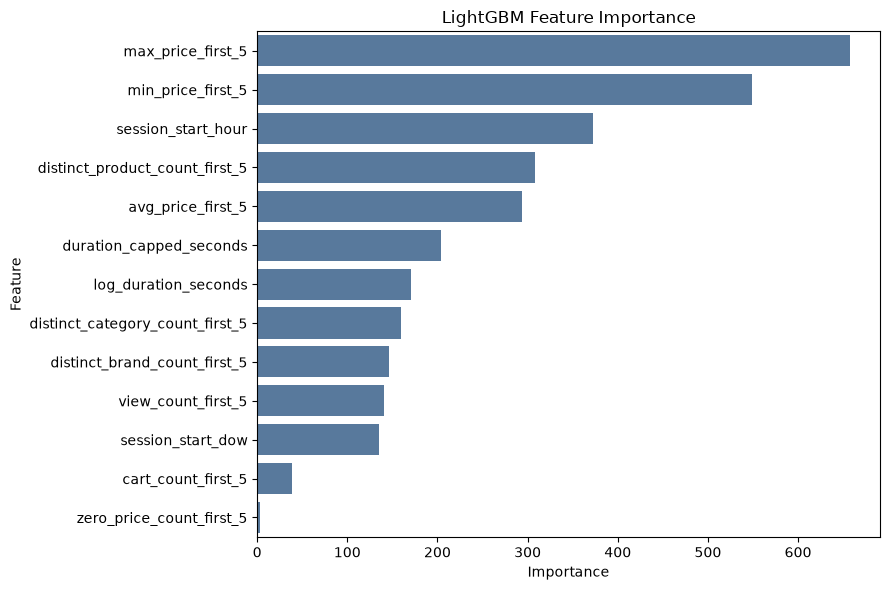

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="importance",
    y="feature",
    color="#4C78A8"
)

plt.title("LightGBM Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### LightGBM 特征重要性解释

按照 LightGBM 默认的分裂次数重要性，模型较多使用了前 5 次行为中的最高价格、最低价格、会话开始小时、不同商品数量和平均价格。

这说明会话早期的商品价格结构、访问时间、浏览广度和行为持续时间对购买意向预测具有一定帮助。

`cart_count_first_5` 的重要性较低，不代表加购行为没有业务价值。可能原因是前 5 次行为中出现加购的样本较少，或者其预测信息与其他特征存在重叠。

当前重要性表示特征与预测结果的关联，不表示因果影响，也不能说明特征数值增加会使购买概率上升或下降。价格特征之间以及持续时间特征之间存在相关性，因此各特征的重要性不能简单相加。

In [31]:
#改用Gain重要性
gain_importance = pd.DataFrame({
    "feature": feature_columns,
    "gain": lightgbm_model.booster_.feature_importance(
        importance_type="gain"
    )
})

gain_importance["gain_share_pct"] = (
    gain_importance["gain"]
    / gain_importance["gain"].sum()
    * 100
).round(2)

gain_importance = gain_importance.sort_values(
    "gain",
    ascending=False
).reset_index(drop=True)

gain_importance

,feature,gain,gain_share_pct
0,view_count_first_5,1.449804e+06,47.45
1,cart_count_first_5,5.271425e+05,17.25
2,distinct_category_count_first_5,2.684748e+05,8.79
3,max_price_first_5,2.166229e+05,7.09
4,distinct_product_count_first_5,1.719990e+05,5.63
5,session_start_hour,1.577461e+05,5.16
6,min_price_first_5,1.067027e+05,3.49
7,avg_price_first_5,5.426924e+04,1.78
8,log_duration_seconds,3.607934e+04,1.18
9,distinct_brand_count_first_5,3.157216e+04,1.03


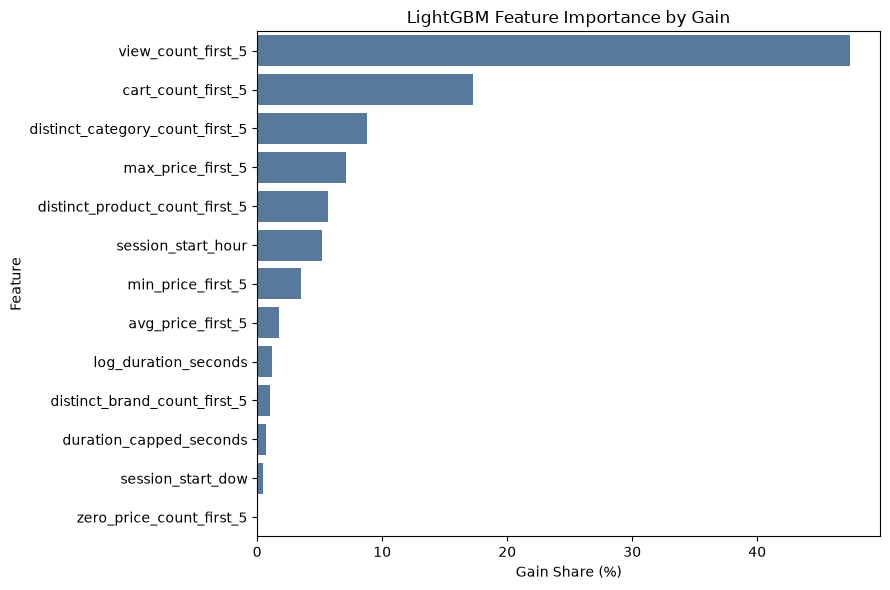

In [32]:
#画图
plt.figure(figsize=(9, 6))

sns.barplot(
    data=gain_importance,
    x="gain_share_pct",
    y="feature",
    color="#4C78A8"
)

plt.title("LightGBM Feature Importance by Gain")
plt.xlabel("Gain Share (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [35]:
'''删除冗余特征：view_count_first_5
duration_capped_seconds
重新训练两个模型
'''
final_feature_columns = [
    "session_start_hour",
    "session_start_dow",
    "cart_count_first_5",
    "distinct_product_count_first_5",
    "distinct_category_count_first_5",
    "distinct_brand_count_first_5",
    "avg_price_first_5",
    "max_price_first_5",
    "min_price_first_5",
    "zero_price_count_first_5",
    "log_duration_seconds",
]
X_train = train_data[final_feature_columns]
y_train = train_data["label"]

X_validation = validation_data[final_feature_columns]
y_validation = validation_data["label"]

X_test = test_data[final_feature_columns]
y_test = test_data["label"]

print("最终特征数量：", len(final_feature_columns))
print("训练集：", X_train.shape)
print("验证集：", X_validation.shape)
print("测试集：", X_test.shape)

最终特征数量： 11
训练集： (1729816, 11)
验证集： (405672, 11)
测试集： (372894, 11)


In [36]:
#逻辑回归
final_logistic_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

final_logistic_model.fit(X_train, y_train)

final_logistic_validation_proba = (
    final_logistic_model.predict_proba(X_validation)[:, 1]
)

final_logistic_test_proba = (
    final_logistic_model.predict_proba(X_test)[:, 1]
)

print("最终逻辑回归训练完成")

最终逻辑回归训练完成


In [37]:
print(
    "验证集 ROC-AUC：",
    round(
        roc_auc_score(
            y_validation,
            final_logistic_validation_proba
        ),
        4
    )
)

print(
    "验证集 PR-AUC：",
    round(
        average_precision_score(
            y_validation,
            final_logistic_validation_proba
        ),
        4
    )
)

print(
    "测试集 ROC-AUC：",
    round(
        roc_auc_score(
            y_test,
            final_logistic_test_proba
        ),
        4
    )
)

print(
    "测试集 PR-AUC：",
    round(
        average_precision_score(
            y_test,
            final_logistic_test_proba
        ),
        4
    )
)

print(
    "测试集 Top 10%：",
    top_k_metrics(
        y_test,
        final_logistic_test_proba
    )
)

验证集 ROC-AUC： 0.7136
验证集 PR-AUC： 0.2262
测试集 ROC-AUC： 0.6935
测试集 PR-AUC： 0.2016
测试集 Top 10%： {'top_fraction_pct': 10.0, 'top_sample_count': 37289, 'top_positive_rate_pct': np.float64(21.12), 'overall_positive_rate_pct': np.float64(6.54), 'recall_at_top_pct': np.float64(32.31), 'lift_at_top': np.float64(3.23)}


In [38]:
#LightGBM
final_lightgbm_model = LGBMClassifier(
    objective="binary",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_lightgbm_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_validation, y_validation)
    ],
    eval_metric="average_precision",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50,
            verbose=False
        ),
        lgb.log_evaluation(period=0)
    ]
)

print(
    "最佳迭代轮数：",
    final_lightgbm_model.best_iteration_
)

C:\Users\29443\Documents\实习\ecommerce-conversion\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 124296, number of negative: 1605520
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.028428 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1081
[LightGBM] [Info] Number of data points in the train set: 1729816, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
最佳迭代轮数： 161


In [39]:
final_lightgbm_validation_proba = (
    final_lightgbm_model.predict_proba(
        X_validation,
        num_iteration=final_lightgbm_model.best_iteration_
    )[:, 1]
)

final_lightgbm_test_proba = (
    final_lightgbm_model.predict_proba(
        X_test,
        num_iteration=final_lightgbm_model.best_iteration_
    )[:, 1]
)

In [40]:
print(
    "测试集 ROC-AUC：",
    round(
        roc_auc_score(
            y_test,
            final_lightgbm_test_proba
        ),
        4
    )
)

print(
    "测试集 PR-AUC：",
    round(
        average_precision_score(
            y_test,
            final_lightgbm_test_proba
        ),
        4
    )
)

print(
    "测试集 Top 10%：",
    top_k_metrics(
        y_test,
        final_lightgbm_test_proba
    )
)

测试集 ROC-AUC： 0.7112
测试集 PR-AUC： 0.2224
测试集 Top 10%： {'top_fraction_pct': 10.0, 'top_sample_count': 37289, 'top_positive_rate_pct': np.float64(22.3), 'overall_positive_rate_pct': np.float64(6.54), 'recall_at_top_pct': np.float64(34.11), 'lift_at_top': np.float64(3.41)}


### 特征冗余检查与调整

Gain 重要性显示，前 5 次浏览数和加购数具有较高预测贡献。但建模样本已排除前 5 次发生购买的会话，因此前 5 次行为只包含浏览和加购，并且始终满足：

`view_count_first_5 + cart_count_first_5 = 5`

两者提供完全重复的信息。为避免逻辑回归中的完全共线性和模型重要性的重复分配，最终模型删除 `view_count_first_5`，保留更具业务意义的 `cart_count_first_5`。

`duration_capped_seconds` 和 `log_duration_seconds` 同样来源于原始持续时间。最终模型仅保留 `log_duration_seconds`，用对数变换降低极端长会话的影响。

此外，默认分裂次数重要性容易偏向具有较多候选切分点的连续变量，因此最终主要参考 Gain 重要性，但特征重要性仍只表示预测关联，不代表因果影响。

### 最终模型结果

在时间外测试集上，逻辑回归取得 ROC-AUC 0.6935、PR-AUC 0.2016、Recall@Top 10% 32.31% 和 Lift@Top 10% 3.23。

LightGBM 取得 ROC-AUC 0.7112、PR-AUC 0.2224、Recall@Top 10% 34.11% 和 Lift@Top 10% 3.41，整体优于逻辑回归，说明会话早期行为与后续购买之间存在一定的非线性关系或特征交互。

删除浏览次数和截断持续时间等冗余特征后，模型表现基本保持稳定，说明模型性能并未依赖这些重复信息。最终模型以 LightGBM 作为主要预测模型，以逻辑回归作为可解释基线模型。

在测试集中，LightGBM 预测分数最高的 10% 会话实际购买率为 22.30%，整体购买率为 6.54%，Lift 为 3.41，并覆盖 34.11% 的真实后续购买会话。该结果表示模型具有一定的目标人群筛选价值，但不代表触达策略产生了因果提升，策略效果仍需通过随机 A/B 实验验证。

## 6. 模型概率校准

ROC-AUC、PR-AUC 和 Lift 用于评价模型的排序能力，但不能保证预测概率与真实购买率一致。

本项目使用了 `class_weight="balanced"` 处理类别不平衡，这可能使模型输出概率偏离真实购买概率。因此，使用验证集拟合概率校准器，并仅在测试集评价校准效果。

概率校准不会用于提高排序指标，而是为了让预测概率更接近实际发生率，便于后续制定触达阈值和估算目标人群规模。

In [41]:
#计算校准前指标
from sklearn.metrics import brier_score_loss, log_loss

uncalibrated_metrics = {
    "brier_score": brier_score_loss(
        y_test,
        final_lightgbm_test_proba
    ),
    "log_loss": log_loss(
        y_test,
        final_lightgbm_test_proba
    ),
    "mean_predicted_probability": (
        final_lightgbm_test_proba.mean()
    ),
    "actual_positive_rate": y_test.mean(),
}

for name, value in uncalibrated_metrics.items():
    print(name, ":", round(value, 4))

brier_score : 0.1945
log_loss : 0.5815
mean_predicted_probability : 0.4261
actual_positive_rate : 0.0654


In [42]:
#使用验证集进行 Sigmoid 校准
import numpy as np
from sklearn.linear_model import LogisticRegression

epsilon = 1e-6

validation_clipped = np.clip(
    final_lightgbm_validation_proba,
    epsilon,
    1 - epsilon
)

test_clipped = np.clip(
    final_lightgbm_test_proba,
    epsilon,
    1 - epsilon
)

validation_logit = np.log(
    validation_clipped / (1 - validation_clipped)
).reshape(-1, 1)

test_logit = np.log(
    test_clipped / (1 - test_clipped)
).reshape(-1, 1)

probability_calibrator = LogisticRegression(
    random_state=42
)

probability_calibrator.fit(
    validation_logit,
    y_validation
)

calibrated_test_proba = (
    probability_calibrator.predict_proba(test_logit)[:, 1]
)

print(
    "校准后平均预测概率：",
    round(calibrated_test_proba.mean(), 4)
)

print(
    "测试集真实购买率：",
    round(y_test.mean(), 4)
)

校准后平均预测概率： 0.0662
测试集真实购买率： 0.0654


In [43]:
#比较校准前后
calibration_comparison = pd.DataFrame({
    "metric": [
        "Brier Score",
        "Log Loss",
        "Mean Predicted Probability",
        "ROC-AUC",
        "PR-AUC",
    ],
    "before_calibration": [
        brier_score_loss(
            y_test,
            final_lightgbm_test_proba
        ),
        log_loss(
            y_test,
            final_lightgbm_test_proba
        ),
        final_lightgbm_test_proba.mean(),
        roc_auc_score(
            y_test,
            final_lightgbm_test_proba
        ),
        average_precision_score(
            y_test,
            final_lightgbm_test_proba
        ),
    ],
    "after_calibration": [
        brier_score_loss(
            y_test,
            calibrated_test_proba
        ),
        log_loss(
            y_test,
            calibrated_test_proba
        ),
        calibrated_test_proba.mean(),
        roc_auc_score(
            y_test,
            calibrated_test_proba
        ),
        average_precision_score(
            y_test,
            calibrated_test_proba
        ),
    ],
})

calibration_comparison

,metric,before_calibration,after_calibration
0,Brier Score,0.194517,0.056093
1,Log Loss,0.581464,0.216888
2,Mean Predicted Probability,0.426088,0.066163
3,ROC-AUC,0.711168,0.711168
4,PR-AUC,0.222429,0.222429


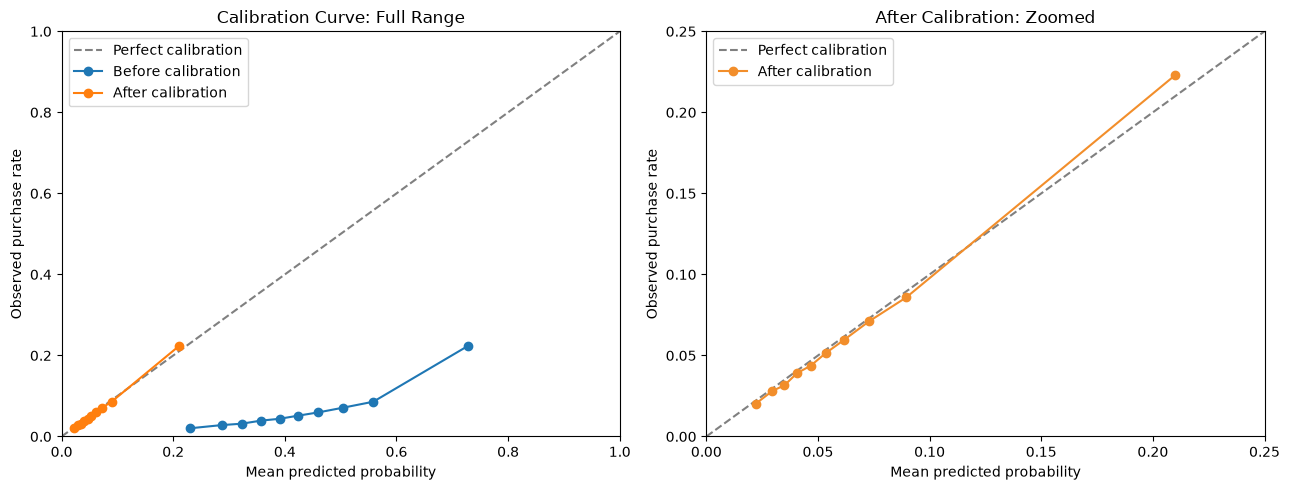

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 左图：完整范围，用于展示校准前的概率高估
axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

axes[0].plot(
    before_pred,
    before_true,
    marker="o",
    label="Before calibration"
)

axes[0].plot(
    after_pred,
    after_true,
    marker="o",
    label="After calibration"
)

axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].set_title("Calibration Curve: Full Range")
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Observed purchase rate")
axes[0].legend()


# 右图：放大校准后的有效概率区间
axes[1].plot(
    [0, 0.25],
    [0, 0.25],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

axes[1].plot(
    after_pred,
    after_true,
    marker="o",
    color="#F28E2B",
    label="After calibration"
)

axes[1].set_xlim(0, 0.25)
axes[1].set_ylim(0, 0.25)
axes[1].set_title("After Calibration: Zoomed")
axes[1].set_xlabel("Mean predicted probability")
axes[1].set_ylabel("Observed purchase rate")
axes[1].legend()

plt.tight_layout()
figure_dir = Path("../reports/figures").resolve()
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "lightgbm_calibration_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.show()

In [47]:
#生成校准分组表
calibration_table = pd.DataFrame({
    "calibrated_probability": calibrated_test_proba,
    "label": y_test.to_numpy()
})

calibration_table["probability_group"] = pd.qcut(
    calibration_table["calibrated_probability"],
    q=10,
    labels=[
        "D1", "D2", "D3", "D4", "D5",
        "D6", "D7", "D8", "D9", "D10"
    ],
    duplicates="drop"
)

calibration_table = (
    calibration_table
    .groupby("probability_group", observed=True)
    .agg(
        sample_count=("label", "size"),
        mean_predicted_probability=(
            "calibrated_probability",
            "mean"
        ),
        observed_purchase_rate=("label", "mean"),
        purchase_count=("label", "sum")
    )
    .reset_index()
)

calibration_table[
    "mean_predicted_probability_pct"
] = (
    calibration_table["mean_predicted_probability"] * 100
).round(2)

calibration_table[
    "observed_purchase_rate_pct"
] = (
    calibration_table["observed_purchase_rate"] * 100
).round(2)

calibration_table[
    [
        "probability_group",
        "sample_count",
        "mean_predicted_probability_pct",
        "observed_purchase_rate_pct",
        "purchase_count"
    ]
]

,probability_group,sample_count,mean_predicted_probability_pct,observed_purchase_rate_pct,purchase_count
0,D1,37290,2.22,2.03,758
1,D2,37289,2.96,2.81,1049
2,D3,37290,3.50,3.16,1178
3,D4,37289,4.06,3.91,1457
4,D5,37289,4.67,4.37,1630
5,D6,37289,5.34,5.14,1917
6,D7,37290,6.16,5.96,2221
7,D8,37290,7.29,7.11,2652
8,D9,37288,8.95,8.58,3199
9,D10,37290,21.00,22.30,8315


### 概率校准结论

原始 LightGBM 使用类别平衡权重后，测试集平均预测概率为 42.61%，明显高于真实购买率 6.54%，因此原始概率不适合直接解释为购买概率。

使用验证集进行 Sigmoid 校准后，测试集平均预测概率下降至 6.62%，接近真实购买率。Brier Score 从 0.1945 降至 0.0561，Log Loss 从 0.5815 降至 0.2169。

局部校准曲线整体接近理想线。最高预测概率组存在轻微低估，但总体概率质量已明显改善。校准没有改变 ROC-AUC 和 PR-AUC，因为它主要重新映射概率，而没有改变样本排序。

### 校准分组表解释

校准分组表将测试集按预测概率从低到高分为 10 组，每组约包含 10% 的会话。随着预测概率分组从 D1 升高到 D10，实际购买率也整体递增，说明模型具有良好的排序能力。

各组预测概率与实际购买率存在小幅差异。例如 D10 组的平均预测概率为 21.00%，实际购买率为 22.30%，相差 1.30 个百分点。由于校准器在验证集上拟合、在测试集上评价，加上测试集本身存在抽样波动，各分组不可能完全一致。

整体平均预测概率为 6.62%，实际购买率为 6.54%，仅相差 0.08 个百分点，说明总体校准效果良好。

In [48]:
final_model_summary = pd.DataFrame({
    "model": [
        "Logistic Regression",
        "LightGBM"
    ],
    "test_roc_auc": [
        roc_auc_score(
            y_test,
            final_logistic_test_proba
        ),
        roc_auc_score(
            y_test,
            final_lightgbm_test_proba
        )
    ],
    "test_pr_auc": [
        average_precision_score(
            y_test,
            final_logistic_test_proba
        ),
        average_precision_score(
            y_test,
            final_lightgbm_test_proba
        )
    ],
    "recall_at_top_10_pct": [
        32.31,
        34.11
    ],
    "lift_at_top_10": [
        3.23,
        3.41
    ]
})

final_model_summary.round(4)

,model,test_roc_auc,test_pr_auc,recall_at_top_10_pct,lift_at_top_10
0,Logistic Regression,0.6935,0.2016,32.31,3.23
1,LightGBM,0.7112,0.2224,34.11,3.41


### 最终模型选择

LightGBM 在测试集上的 ROC-AUC、PR-AUC、Recall@Top 10% 和 Lift@Top 10% 均优于逻辑回归，因此选择 LightGBM 作为最终预测模型，逻辑回归作为可解释基线。

LightGBM 测试集 ROC-AUC 为 0.7112，PR-AUC 为 0.2224。预测分数最高的 10% 会话覆盖了 34.11% 的真实后续购买会话，其购买率是总体平均水平的 3.41 倍。

模型的主要价值是对会话进行购买意向排序，从有限流量中筛选更值得触达的对象，而不是准确判断每个会话一定购买或不购买。

## 7. 最终结论

- 以会话前 5 次行为预测后续购买，共构造 2,508,382 个样本，正样本比例为 7.12%。
- 使用时间切分进行训练、验证和测试，避免随机切分造成过于乐观的结果。
- LightGBM 在时间外测试集上取得 ROC-AUC 0.7112、PR-AUC 0.2224，整体优于逻辑回归。
- LightGBM 预测分数最高的 10% 会话覆盖 34.11% 的真实购买会话，购买率约为整体平均水平的 3.41 倍。
- 概率校准后，平均预测概率从 42.61% 调整至 6.62%，接近真实购买率 6.54%。
- 模型适合用于高购买意向会话筛选，但模型关联不能解释为因果影响，触达策略仍需通过 A/B 实验验证。